# Consumer Complaint Classification — Step 1: Data Understanding, Cleaning & Splitting
**Goal of this notebook:** load the data, understand it, clean it *before* splitting (no leakage), and save train/val/test files that every later model (SimpleRNN, LSTM, GRU, DistilBERT) will reuse.

## 1.1 Setup & load

In [1]:
import os, glob, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

SEED = 42
random.seed(SEED); np.random.seed(SEED)

# --- Find the CSV automatically (Kaggle input dir or current folder) ---
candidates = glob.glob('/kaggle/input/**/complaints_processed.csv', recursive=True) + glob.glob('complaints_processed.csv')
DATA_PATH = candidates[0]
print('Using:', DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

Using: /kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv
(162421, 3)


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...


## 1.2 First look

In [2]:
print(df.dtypes, '\n')
print('Nulls:\n', df.isna().sum(), '\n')
print('Classes:\n', df['product'].value_counts())

Unnamed: 0     int64
product       object
narrative     object
dtype: object 

Nulls:
 Unnamed: 0     0
product        0
narrative     10
dtype: int64 

Classes:
 product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64


## 1.3 Cleaning (done BEFORE splitting)
Why before? If the same complaint appears twice, one copy can land in train and one in test → the model "sees the answer" → fake high score (**data leakage**).

Order matters:
1. Drop the old index column `Unnamed: 0` — it makes identical rows look different, hiding duplicates.
2. Drop empty narratives.
3. Drop exact duplicate rows.
4. Drop narratives that appear with **different labels** (conflicting labels = noise we can't resolve).
5. Drop extremely short texts (< 3 words) — nothing to learn from.

In [3]:
n0 = len(df)
df = df.drop(columns=['Unnamed: 0'], errors='ignore')
df = df.dropna(subset=['narrative']).copy()
print('after dropna            :', len(df))

df = df.drop_duplicates()
print('after exact duplicates  :', len(df))

n_labels = df.groupby('narrative')['product'].nunique()
conflicting = n_labels[n_labels > 1].index
print('conflicting narratives  :', len(conflicting))
df = df[~df['narrative'].isin(conflicting)].drop_duplicates(subset='narrative')
print('after conflicts + dups  :', len(df))

df['n_words'] = df['narrative'].str.split().str.len()
df = df[df['n_words'] >= 3].reset_index(drop=True)
print('after short-text filter :', len(df))
print(f'\nRemoved {n0-len(df):,} rows ({(n0-len(df))/n0:.1%})')

after dropna            : 162411
after exact duplicates  : 124676
conflicting narratives  : 172
after conflicts + dups  : 124300
after short-text filter : 124164

Removed 38,257 rows (23.6%)


## 1.4 What does the text look like?
The dataset is **already preprocessed** (lowercase, no punctuation/numbers, stop words removed, lemmatized). Let's verify it instead of redoing it blindly.

In [4]:
import re
sample = df['narrative'].sample(3, random_state=SEED).tolist()
for s in sample: print(s[:300], '\n')

print('Has uppercase letters :', df['narrative'].str.contains(r'[A-Z]').mean())
print('Has digits            :', df['narrative'].str.contains(r'\d').mean())
print('Has punctuation       :', df['narrative'].str.contains(r'[^\w\s]').mean())
print('Has "the"/"and"/"not" :', df['narrative'].str.contains(r'\b(?:the|and|not)\b').mean())

went get gas gas station charge still pending gas station held however also reversal credit also still pending according app according paperwork received debit card banker debit card charge correct amount actually spent spoke customer service representative calling listed paperwork received mail tol 

lvnv funding llc sent collection letter dated postmarked received informing debt proceeded report collection well day violating fdcpa right dispute debt requested received anything back sending new letter requesting delete information received investigation result day week additionally receive colle 

reporting department education balance twice charge show separate time updated pandemic care act put halt student loan paid promised would removed trusted department education paid close money extremely tight honor word reporting account twice leaving making getting transportation housing much harde 

Has uppercase letters : 0.0
Has digits            : 0.0
Has punctuation       : 0.0
Has "th

## 1.5 Class distribution (imbalance?)

product
credit_reporting       0.452
debt_collection        0.169
mortgages_and_loans    0.151
credit_card            0.121
retail_banking         0.108
Name: count, dtype: float64


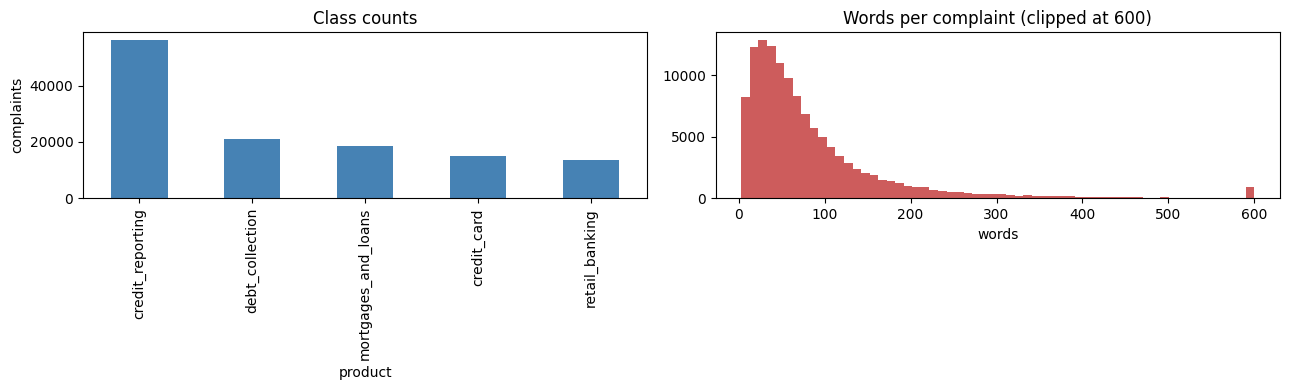

count    124164.0
mean         87.3
std         111.0
min           3.0
50%          58.0
75%         104.0
90%         180.0
95%         253.0
99%         502.0
max        2685.0
Name: n_words, dtype: float64


In [5]:
counts = df['product'].value_counts()
print((counts/len(df)).round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
counts.plot.bar(ax=ax[0], color='steelblue'); ax[0].set_title('Class counts'); ax[0].set_ylabel('complaints')
ax[1].hist(df['n_words'].clip(upper=600), bins=60, color='indianred')
ax[1].set_title('Words per complaint (clipped at 600)'); ax[1].set_xlabel('words')
plt.tight_layout(); plt.show()

print(df['n_words'].describe(percentiles=[.5,.75,.9,.95,.99]).round(1))

**Reading the results:**
- `credit_reporting` is ~45% of the data, the smallest class ~11% → **moderately imbalanced** → we'll use **class weights** and report **macro-F1** (not accuracy alone).
- Median length ≈ 58 words, 95% under ≈ 250 words → later we pad/truncate to a fixed length (~250) so we don't waste memory on rare very long texts.

## 1.6 Encode labels & split (stratified 70 / 15 / 15)

In [6]:
classes = sorted(df['product'].unique())
label2id = {c: i for i, c in enumerate(classes)}
id2label = {i: c for c, i in label2id.items()}
df['label'] = df['product'].map(label2id)
print(label2id)

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label'], random_state=SEED)

for name, d in [('train', train_df), ('val', val_df), ('test', test_df)]:
    print(f'{name:5s} {len(d):7,d}  ', d['label'].value_counts(normalize=True).sort_index().round(3).tolist())

# safety check: no text shared between splits
assert not set(train_df.narrative) & set(test_df.narrative)
assert not set(train_df.narrative) & set(val_df.narrative)
assert not set(val_df.narrative) & set(test_df.narrative)
print('\nNo overlap between splits ✔')

{'credit_card': 0, 'credit_reporting': 1, 'debt_collection': 2, 'mortgages_and_loans': 3, 'retail_banking': 4}
train  86,914   [0.12, 0.452, 0.169, 0.151, 0.108]
val    18,625   [0.12, 0.452, 0.169, 0.151, 0.108]
test   18,625   [0.121, 0.452, 0.169, 0.151, 0.108]

No overlap between splits ✔


## 1.7 Save splits (reused by ALL models → fair comparison)

In [7]:
os.makedirs('splits', exist_ok=True)
cols = ['narrative', 'label', 'product']
train_df[cols].to_csv('splits/train.csv', index=False)
val_df[cols].to_csv('splits/val.csv', index=False)
test_df[cols].to_csv('splits/test.csv', index=False)
import json; json.dump(label2id, open('splits/label2id.json', 'w'))
print(os.listdir('splits'))

['label2id.json', 'val.csv', 'test.csv', 'train.csv']
